
# Model 11: Interacting Neurons

## Objective

Construct a network of interconnected neurons whose activities influence one another through weighted synaptic connections.

Unlike previous models, which focused on individual synaptic weights, this model investigates how neural activity propagates through a network.

## Research Questions

1. How does activating one neuron influence the activity of others?
2. How do excitatory and inhibitory connections affect network behavior?
3. Can patterns of neural activity emerge from local interactions?

## Hypothesis

Stimulating one neuron will cause activity to propagate through excitatory connections, while inhibitory connections will suppress the activation of certain neurons.

## Model Assumptions

- Neurons have binary activity states: 0 (inactive) or 1 (active).
- Connections between neurons have fixed synaptic weights.
- Positive weights represent excitatory connections.
- Negative weights represent inhibitory connections.
- A neuron activates when its total input reaches a threshold.
- All neurons update their states simultaneously.

This model focuses on neural interactions rather than learning. Synaptic weight updates will be introduced in future models.


In [5]:

import numpy as np
import matplotlib.pyplot as plt

num_neurons = 6
threshold = 1.0

# Initialize the weight matrix
W = np.zeros((num_neurons, num_neurons))

# Excitatory connections
W[1, 0] = 1.2  # Neuron 1 -> 2
W[2, 1] = 1.1  # Neuron 2 -> 3
W[3, 2] = 1.2  # Neuron 3 -> 4
W[4, 1] = 1.1  # Neuron 2 -> 5
W[5, 2] = 1.1  # Neuron 3 -> 6

# Inhibitory connection
W[4, 3] = -1.5 # Neuron 4 inhibits neuron 5

# Feedback connections
W[2, 3] = 0.25 # Neuron 4 -> 3
W[1, 5] = 0.2  # Neuron 6 -> 2

# External stimulation to neuron 1
bias = np.array([1.2, 0, 0, 0, 0, 0])

print(W)


[[ 0.    0.    0.    0.    0.    0.  ]
 [ 1.2   0.    0.    0.    0.    0.2 ]
 [ 0.    1.1   0.    0.25  0.    0.  ]
 [ 0.    0.    1.2   0.    0.    0.  ]
 [ 0.    1.1   0.   -1.5   0.    0.  ]
 [ 0.    0.    1.1   0.    0.    0.  ]]


In [6]:

def update_neurons(activities, W, bias, threshold):
    inputs = W @ activities + bias

    return (inputs >= threshold).astype(int)


In [7]:

steps = 10

activities = np.array([1, 0, 0, 0, 0, 0])

history = [activities.copy()]

for t in range(steps):
    activities = update_neurons(
        activities, W, bias, threshold
    )

    history.append(activities.copy())

history = np.array(history)

print(history)


[[1 0 0 0 0 0]
 [1 1 0 0 0 0]
 [1 1 1 0 1 0]
 [1 1 1 1 1 1]
 [1 1 1 1 0 1]
 [1 1 1 1 0 1]
 [1 1 1 1 0 1]
 [1 1 1 1 0 1]
 [1 1 1 1 0 1]
 [1 1 1 1 0 1]
 [1 1 1 1 0 1]]


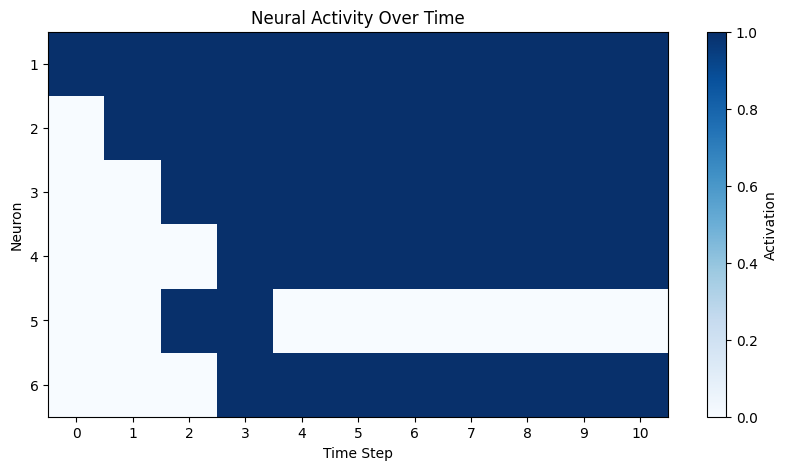

In [8]:

plt.figure(figsize=(10, 5))

plt.imshow(
    history.T,
    cmap="Blues",
    aspect="auto",
    vmin=0,
    vmax=1
)

plt.xlabel("Time Step")
plt.ylabel("Neuron")
plt.title("Neural Activity Over Time")

plt.xticks(range(steps + 1))
plt.yticks(range(num_neurons),
           range(1, num_neurons + 1))

plt.colorbar(label="Activation")
plt.show()
